## 一、数据获取与建库

数据源：新浪财经公开财报接口（akshare `stock_financial_report_sina`）。
对象：贵州茅台（600519）、五粮液（000858）、泸州老窖（000568）。
将三家公司 1998 年至今的利润表与资产负债表分别写入本地 SQLite 数据库。

In [52]:
import akshare as ak 
import sqlite3 
import time

stocks = { "sh600519" : "贵州茅台" , "sz000858" : "五粮液" , "sz000568" : "泸州老窖" }
conn = sqlite3.connect( r"D:\finance_analysis\数据\finance.db" ) 
for code, name in stocks.items(): 
    for report in [ "利润表" , "资产负债表" ]:
        df = ak.stock_financial_report_sina(stock=code, symbol=report)
        table = f"{name}_{report}" 
        df.to_sql(table, conn, if_exists= "replace" , index= False ) 
        print (table, df.shape)
        time.sleep( 2 )

conn.close()
print ( "全部完成" )

贵州茅台_利润表 (103, 83)
贵州茅台_资产负债表 (103, 147)
五粮液_利润表 (111, 83)
五粮液_资产负债表 (111, 147)
泸州老窖_利润表 (117, 83)
泸州老窖_资产负债表 (117, 147)
全部完成


## 二、指标计算

口径说明：
- 净利率 = 归母净利润 ÷ 营业总收入
- 营收增速 = （本期营收 − 上期营收）÷ 上期营收，使用 `LAG` 窗口函数
- ROE = 归母净利润 ÷ 平均归母股东权益（期初与期末均值）
- 仅保留报告日以 `1231` 结尾的年报数据

In [53]:
import sqlite3

conn = sqlite3.connect(r"D:\finance_analysis\数据\finance.db")

df_bs = pd.read_sql("select * FROM 贵州茅台_资产负债表 LIMIT 1",conn)
print(df_bs.columns.tolist())

['报告日', '流动资产', '货币资金', '结算备付金', '拆出资金', '交易性金融资产', '买入返售金融资产', '衍生金融资产', '应收票据及应收账款', '应收票据', '应收账款', '应收款项融资', '预付款项', '应收股利', '应收利息', '应收保费', '应收分保账款', '应收分保合同准备金', '应收出口退税', '应收补贴款', '应收保证金', '内部应收款', '其他应收款', '其他应收款(合计)', '存货', '划分为持有待售的资产', '待摊费用', '待处理流动资产损益', '一年内到期的非流动资产', '其他流动资产', '流动资产合计', '非流动资产', '发放贷款及垫款', '债权投资', '其他债权投资', '以公允价值计量且其变动计入其他综合收益的金融资产', '以摊余成本计量的金融资产', '可供出售金融资产', '长期股权投资', '投资性房地产', '长期应收款', '其他权益工具投资', '其他非流动金融资产', '其他长期投资', '固定资产原值', '累计折旧', '固定资产净值', '固定资产减值准备', '在建工程合计', '在建工程', '工程物资', '固定资产净额', '固定资产清理', '固定资产及清理合计', '生产性生物资产', '公益性生物资产', '油气资产', '合同资产', '使用权资产', '无形资产', '开发支出', '商誉', '长期待摊费用', '股权分置流通权', '递延所得税资产', '其他非流动资产', '非流动资产合计', '资产总计', '流动负债', '短期借款', '向中央银行借款', '吸收存款及同业存放', '拆入资金', '交易性金融负债', '衍生金融负债', '应付票据及应付账款', '应付票据', '应付账款', '预收款项', '合同负债', '卖出回购金融资产款', '应付手续费及佣金', '应付职工薪酬', '应交税费', '应付利息', '应付股利', '应付保证金', '内部应付款', '其他应付款', '其他应付款合计', '其他应交款', '担保责任赔偿准备金', '应付分保账款', '保险合同准备金', '代理买卖证券款', '代理承销证券款', '国际票证结算', '国内票证结算', '预提费用', '预计流动

In [70]:
stocks = {"贵州茅台": "sh600519", "五粮液": "sz000858", "泸州老窖": "sz000568"}

# 用字典存三家的结果，key 是公司名
profit = {}  # 净利率 + 营收增速
roe = {}     # ROE

for name in stocks:
    # 利润指标
    sql_p = f"""
    SELECT CAST(报告日 AS TEXT) AS 年份,
           ROUND(营业总收入 / 100000000.0, 2) AS 营收_亿元,
           ROUND(归属于母公司所有者的净利润 / 100000000.0, 2) AS 归母净利润_亿元,
           ROUND(归属于母公司所有者的净利润 * 100.0 / 营业总收入, 2) AS 净利率,
           ROUND((营业总收入 - LAG(营业总收入) OVER (ORDER BY 报告日)) * 100.0
                 / LAG(营业总收入) OVER (ORDER BY 报告日), 2) AS 营收增速
    FROM {name}_利润表
    WHERE CAST(报告日 AS TEXT) LIKE '%1231'
    ORDER BY 报告日
    """
    profit[name] = pd.read_sql(sql_p, conn)

    # ROE
    sql_r = f"""
    WITH bs AS (
        SELECT CAST(报告日 AS TEXT) AS 年份,
               CAST(归属于母公司股东权益合计 AS REAL) AS 权益
        FROM {name}_资产负债表
        WHERE CAST(报告日 AS TEXT) LIKE '%1231'
    ),
    pl AS (
        SELECT CAST(报告日 AS TEXT) AS 年份,
               CAST(归属于母公司所有者的净利润 AS REAL) AS 净利润
        FROM {name}_利润表
        WHERE CAST(报告日 AS TEXT) LIKE '%1231'
    )
    SELECT p.年份,
           ROUND(p.净利润 * 100.0 / ((b.权益 + LAG(b.权益) OVER (ORDER BY b.年份)) / 2), 2) AS ROE
    FROM pl p JOIN bs b ON p.年份 = b.年份
    ORDER BY p.年份
    """
    roe[name] = pd.read_sql(sql_r, conn)
    print(f"{name} 完成，{len(roe[name])} 行")

# 显示三家最近5年 ROE（这个循环必须在外面，不能缩进进上面的 for）
for name in stocks:
    print(f"\n=== {name} 最近5年 ROE ===")
    print(roe[name].tail(5).to_string(index=False))


贵州茅台 完成，28 行
五粮液 完成，31 行
泸州老窖 完成，35 行

=== 贵州茅台 最近5年 ROE ===
      年份   ROE
20211231 29.90
20221231 32.41
20231231 36.18
20241231 38.43
20251231 34.46

=== 五粮液 最近5年 ROE ===
      年份   ROE
20211231 25.30
20221231 25.05
20231231 24.80
20241231 24.24
20251231  7.07

=== 泸州老窖 最近5年 ROE ===
      年份   ROE
20211231 31.13
20221231 33.30
20231231 35.04
20241231 30.35
20251231 22.29


## 三、可视化

对比窗口取 2015—2024 年。2025 年年报中五粮液营业收入较上年下降 54.55%，与同业走势严重背离，判断为数据源异常，故不纳入图表。

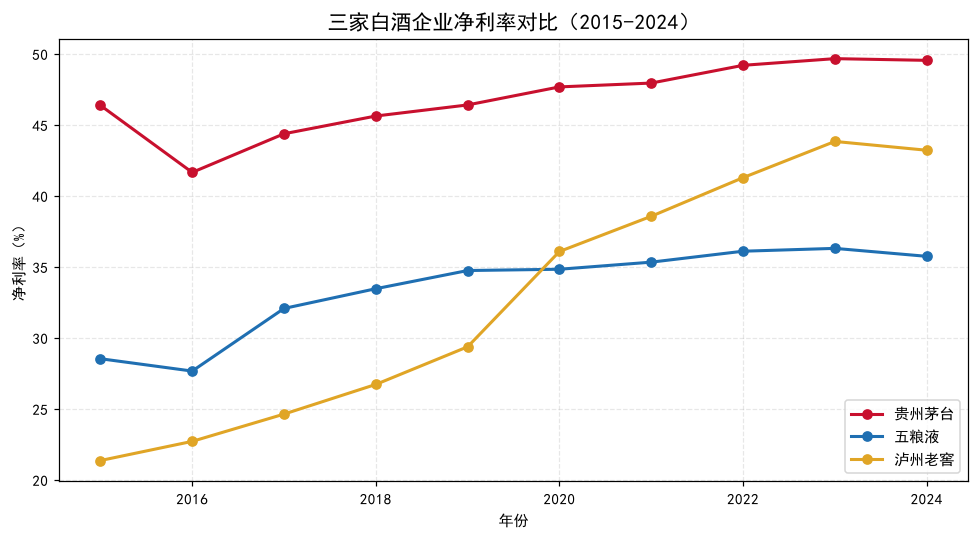

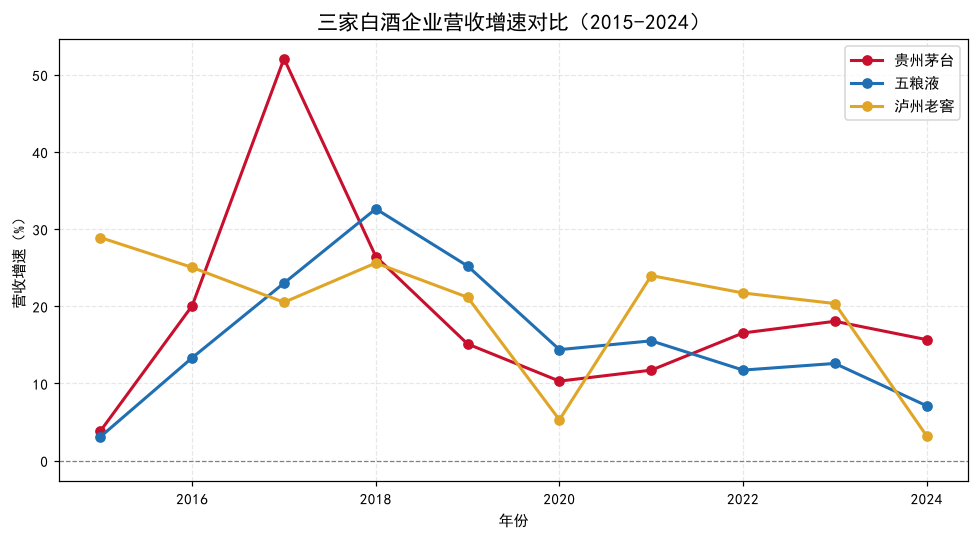

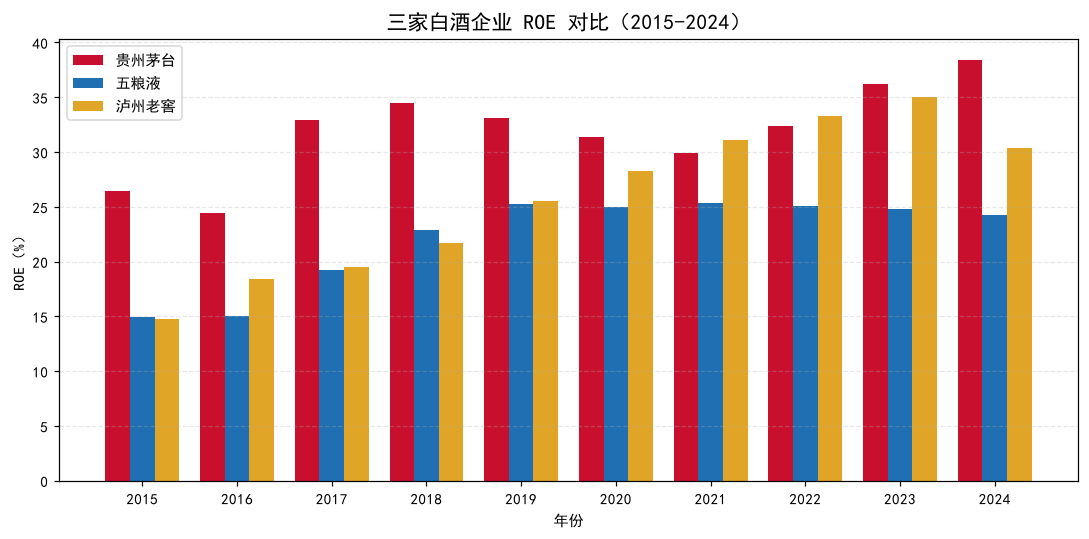

三张图已保存到 D:\finance_analysis\


In [71]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

START, END = "20150101", "20241231"
colors = {"贵州茅台": "#C8102E", "五粮液": "#1F6FB2", "泸州老窖": "#E0A526"}

def window(df, col):
    d = df[(df["年份"] >= START) & (df["年份"] <= END)].copy()
    d["年"] = d["年份"].str[:4].astype(int)
    return d.set_index("年")[col]

# 图1：净利率
plt.figure(figsize=(9, 4.3))
for name in stocks:
    s = window(profit[name], "净利率")
    plt.plot(s.index, s.values, marker="o", linewidth=2, label=name, color=colors[name])
plt.title("三家白酒企业净利率对比（2015-2024）", fontsize=14)
plt.xlabel("年份"); plt.ylabel("净利率（%）")
plt.grid(alpha=0.3, linestyle="--"); plt.legend()
plt.tight_layout()
plt.savefig(r"D:\finance_analysis\图表\图1_净利率对比.png", dpi=150)
plt.show()

# 图2：营收增速
plt.figure(figsize=(9, 4.3))
for name in stocks:
    s = window(profit[name], "营收增速")
    plt.plot(s.index, s.values, marker="o", linewidth=2, label=name, color=colors[name])
plt.axhline(0, color="gray", linewidth=0.8, linestyle="--")
plt.title("三家白酒企业营收增速对比（2015-2024）", fontsize=14)
plt.xlabel("年份"); plt.ylabel("营收增速（%）")
plt.grid(alpha=0.3, linestyle="--"); plt.legend()
plt.tight_layout()
plt.savefig(r"D:\finance_analysis\图表\图2_营收增速对比.png", dpi=150)
plt.show()

# 图3：ROE 分组柱状
years = list(range(2015, 2025))
x = np.arange(len(years)); w = 0.26
plt.figure(figsize=(10, 4.6))
for i, name in enumerate(stocks):
    s = window(roe[name], "ROE").reindex(years)
    plt.bar(x + (i - 1) * w, s.values, width=w, label=name, color=colors[name])
plt.xticks(x, years)
plt.title("三家白酒企业 ROE 对比（2015-2024）", fontsize=14)
plt.xlabel("年份"); plt.ylabel("ROE（%）")
plt.grid(alpha=0.3, axis="y", linestyle="--"); plt.legend()
plt.tight_layout()
plt.savefig(r"D:\finance_analysis\图表\图3_ROE对比.png", dpi=150)
plt.show()

print("三张图已保存到 D:\\finance_analysis\\图表\\")
